# Store Sales — Step 3: Baseline (Random Walk)

**Author:** Bella Ren

The official baseline is a **random walk**, i.e. ARIMA(0,1,0) without drift.
The forecast for every future day equals the last observed value:

$$\hat y_{T+h} = y_T, \quad h = 1, \dots, 16$$

Series with zero sales in the last 30 days are forecast as 0.

It is scored with the project-wide backtest in `backtest.py`, which every later model also uses:

| Window | Training data up to | Forecast window | Use |
|---|---|---|---|
| F1 | 2017-06-12 | 06-13 → 06-28 | model development |
| F2 | 2017-06-28 | 06-29 → 07-14 | model development |
| F3 | 2017-07-14 | 07-15 → 07-30 | model development |
| Holdout | 2017-07-30 | 07-31 → 08-15 | final comparison only |

Windows do not overlap, and a model only sees data up to the cutoff (the `sales` column of the forecast window is removed before the model is called), so there is no look-ahead bias.
**The baseline score is the mean RMSLE over F1–F3.**

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import backtest as bt

plt.rcParams['figure.figsize'] = (14, 4)
plt.rcParams['axes.grid'] = True

df = bt.load_panel()
print(df.shape)

(3036528, 25)


## 1. Backtest score (F1–F3)

In [2]:
dev = bt.backtest(bt.random_walk, df, bt.FOLDS, name='random walk')
print('\nBaseline RMSLE (mean of F1–F3): %.4f' % dev['mean'])

random walk                  F1       cutoff 2017-06-12  RMSLE 0.5861
random walk                  F2       cutoff 2017-06-28  RMSLE 0.6051


random walk                  F3       cutoff 2017-07-14  RMSLE 0.5881

Baseline RMSLE (mean of F1–F3): 0.5931


## 2. Holdout score
Reported once for the final comparison; not used to choose or tune anything.

In [3]:
hold = bt.backtest(bt.random_walk, df, bt.HOLDOUT, name='random walk')

random walk                  HOLDOUT  cutoff 2017-07-30  RMSLE 0.6595


## 3. Error by forecast horizon (F1–F3)
The random-walk forecast is flat, so its error depends on how typical the last observed day was
and on the weekly cycle of the target days.

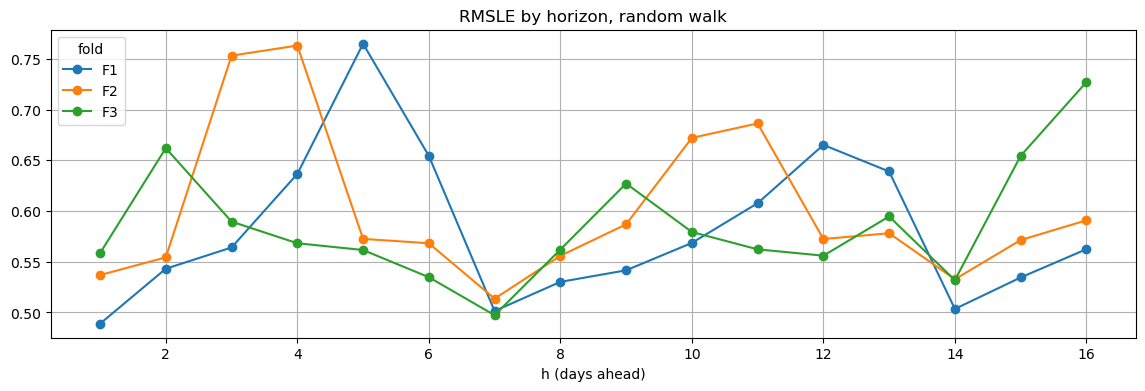

Weekday of each cutoff: {'F1': 'Monday', 'F2': 'Wednesday', 'F3': 'Friday'}


In [4]:
rows = []
for f, cutoff in bt.FOLDS.items():
    out = bt.run_fold(bt.random_walk, df, cutoff)
    out['h'] = (out.date - cutoff).dt.days
    out['fold'] = f
    rows.append(out)
dev_out = pd.concat(rows)
by_h = dev_out.groupby(['h', 'fold']).apply(lambda g: bt.rmsle(g.sales, g.pred), include_groups=False).unstack()
ax = by_h.plot(marker='o', title='RMSLE by horizon, random walk')
ax.set_xlabel('h (days ahead)'); plt.show()
print('Weekday of each cutoff:', {f: c.day_name() for f, c in bt.FOLDS.items()})

## 4. Example series (F3): actual vs random-walk forecast

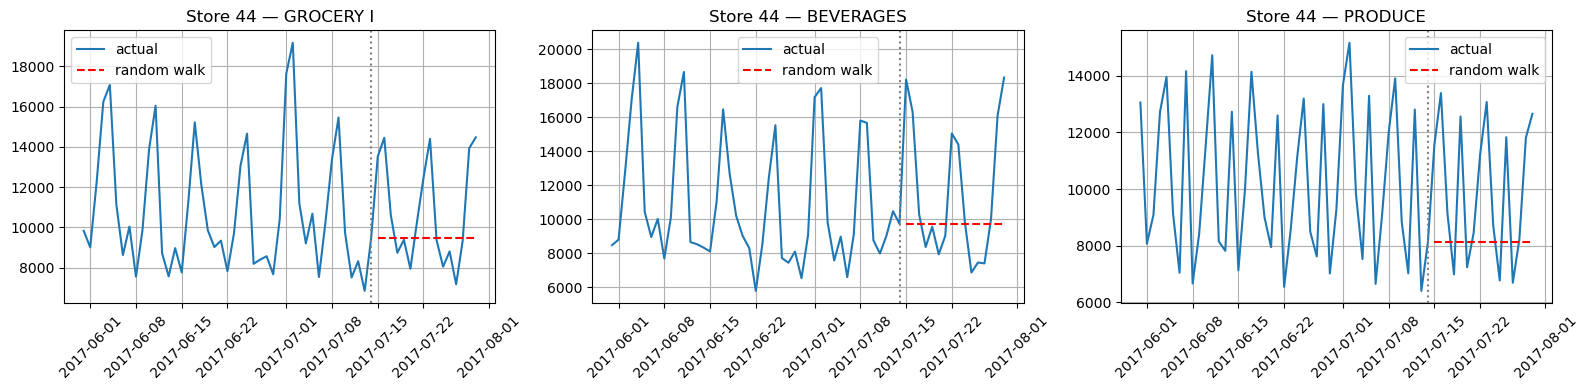

In [5]:
cut = bt.FOLDS['F3']
f3 = dev_out[dev_out.fold == 'F3']
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, fam in zip(axes, ['GROCERY I', 'BEVERAGES', 'PRODUCE']):
    s = df[(df.store_nbr == 44) & (df.family == fam) & (df.date > cut - pd.Timedelta(days=45))
           & (df.date <= cut + pd.Timedelta(days=bt.H))]
    ax.plot(s.date, s.sales, label='actual')
    v = f3[(f3.store_nbr == 44) & (f3.family == fam)]
    ax.plot(v.date, v.pred, 'r--', label='random walk')
    ax.axvline(cut, color='gray', ls=':')
    ax.set_title(f'Store 44 — {fam}'); ax.tick_params(axis='x', rotation=45); ax.legend()
plt.tight_layout(); plt.show()

## 5. Test forecast and submission file
Uses all data up to 2017-08-15 and forecasts 2017-08-16 → 2017-08-31.

In [6]:
import os
history = df[df.date <= bt.TEST_CUTOFF]
future_X = df[df.split == 'test'].drop(columns=['sales'])
pred = bt.finalize(bt.random_walk(history, future_X), history)
sub = future_X[bt.K + ['date', 'id']].merge(pred, on=bt.K + ['date'], how='left')
sub = sub[['id', 'pred']].rename(columns={'pred': 'sales'})
sub['id'] = sub.id.astype(int)
sub = sub.sort_values('id')
assert len(sub) == 28512 and sub.sales.notna().all() and (sub.sales >= 0).all()
os.makedirs('submissions', exist_ok=True)
sub.to_csv('submissions/submission_random_walk.csv', index=False)
print('Saved submissions/submission_random_walk.csv', sub.shape)
sub.head()

Saved submissions/submission_random_walk.csv (28512, 2)


,id,sales
0,3000888,4.0
16,3000889,0.0
32,3000890,4.0
48,3000891,1942.0
64,3000892,0.0
